# Module 7: Production Model Monitoring, Data Drift Detection & Retraining Triggers

## Overview
Once the Ames Housing valuation model (`LGBMRegressor`, 60 selected features) is deployed via FastAPI and Streamlit in **Module 6**, continuous observability is required to protect prediction accuracy against shifting real estate market conditions. This notebook implements a complete production monitoring workflow in English using modular utilities from `src/monitoring.py`.

### Key Objectives
1. **Covariate / Data Drift Tracking:** Compare incoming property listing distributions against the training reference distribution (`X_train_selected.csv`) using **Kolmogorov–Smirnov (KS) two-sample tests**, **Wasserstein distance**, and **Population Stability Index (PSI)**.
2. **Rolling Prediction Error Monitoring:** Track batch-level and sliding-window **RMSE** and **MAE** (on both `log1p` and USD scales) over time as closed sale prices arrive.
3. **Interactive Monitoring Dashboard:** Generate an HTML observability report powered by **Evidently** (with an automatic self-contained governance HTML fallback if `evidently` is not installed).
4. **Automated Retraining Governance:** Evaluate quantitative retraining triggers (drifted feature share, severe PSI threshold, rolling RMSE degradation, and minimum labeled sample volume).

In [4]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root and src/ are importable
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
for p in (PROJECT_ROOT, os.path.join(PROJECT_ROOT, 'src')):
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

from src.monitoring import (
    HAS_EVIDENTLY,
    simulate_production_stream,
    detect_feature_drift,
    compute_rolling_error_metrics,
    evaluate_retraining_triggers,
    generate_monitoring_dashboard,
)

sns.set_theme(style='whitegrid', context='notebook')
print(f'Project Root: {PROJECT_ROOT}')
print(f'Evidently library available: {HAS_EVIDENTLY}')

Project Root: c:\Users\Jonathan\Documents\Development\real-estate-price-prediction_js
Evidently library available: False


## 1. Load Reference Training Data & Production Model Bundle
We load the leak-free training feature matrix (`data/processed/X_train_selected.csv`), the unseen test pool (`data/processed/X_test_selected.csv`), and the serialized LightGBM inference bundle (`models/ames_housing_bundle.joblib`).

In [5]:
data_dir = os.path.join(PROJECT_ROOT, 'data', 'processed')
models_dir = os.path.join(PROJECT_ROOT, 'models')
reports_dir = os.path.join(PROJECT_ROOT, 'reports')
figures_dir = os.path.join(reports_dir, 'figures')
os.makedirs(figures_dir, exist_ok=True)

X_train = pd.read_csv(os.path.join(data_dir, 'X_train_selected.csv'))
X_test = pd.read_csv(os.path.join(data_dir, 'X_test_selected.csv'))
bundle = joblib.load(os.path.join(models_dir, 'ames_housing_bundle.joblib'))

feature_names = bundle['feature_names']
baseline_rmse_log = float(bundle['cv_rmse_log'])

print(f'Model Type: {bundle["model_type"]}')
print(f'Monitored Features: {len(feature_names)}')
print(f'Baseline 5-Fold CV RMSE (log1p): {baseline_rmse_log:.5f}')

Model Type: LGBMRegressor
Monitored Features: 60
Baseline 5-Fold CV RMSE (log1p): 0.13207


## 2. Simulate Incoming Production Listings & Delayed Closing Sales
We simulate **8 weekly batches** (120 listings per week, 960 total transactions):
- **Batches 1–4 (Weeks 1–4):** Stationary market regime matching the training distribution.
- **Batches 5–8 (Weeks 5–8):** Progressive market shift toward newer, higher-quality, larger properties (covariate drift) combined with macro price appreciation (concept drift).

In [6]:
stream_df = simulate_production_stream(
    X_base=X_test,
    bundle=bundle,
    n_batches=8,
    batch_size=120,
    drift_start_batch=5,
    start_date='2026-01-05',
    random_state=42,
)

print(f'Simulated production stream shape: {stream_df.shape}')
stream_df[['batch_id', 'batch_date', 'OverallQual', 'TotalBsmtSF', 'prediction_usd', 'target_usd']].head()

Simulated production stream shape: (960, 66)


,batch_id,batch_date,OverallQual,TotalBsmtSF,prediction_usd,target_usd
0,1,2026-01-05,-1.043292,-0.001189,96129.937212,90313.886378
1,1,2026-01-05,0.548414,1.000760,209449.902276,175832.893223
2,1,2026-01-05,-0.084143,-0.170341,145430.971151,188030.521156
3,1,2026-01-05,-0.516744,-0.387718,133383.827481,139006.043837
4,1,2026-01-05,-0.991862,-0.423985,122586.058179,130521.317625


## 3. Data Drift Analysis (Incoming Listings vs. Training Reference)
We compare the recent production window (**Batches 5–8**, $n = 480$) against the training baseline (**`X_train`**, $n = 1,458$) across all 60 selected features using:
- **Population Stability Index (PSI):** `PSI < 0.10` (stable), `0.10 <= PSI < 0.25` (moderate shift), `PSI >= 0.25` (severe shift).
- **Two-Sample Kolmogorov–Smirnov (KS) Test:** Non-parametric test for distributional divergence ($\alpha = 0.05$).
- **Wasserstein Distance:** Earth Mover's Distance between empirical distributions.

In [7]:
recent_window_df = stream_df[stream_df['batch_id'] >= 5].copy()

drift_df = detect_feature_drift(
    reference_df=X_train[feature_names],
    current_df=recent_window_df[feature_names],
    feature_cols=feature_names,
    ks_alpha=0.05,
    psi_threshold=0.20,
)

n_drifted = int(drift_df['drift_detected'].sum())
print(f'Features with statistically significant drift: {n_drifted} / {len(drift_df)} ({n_drifted / len(drift_df):.1%})')
drift_df.head(12)

Features with statistically significant drift: 18 / 60 (30.0%)


,feature,ref_mean,cur_mean,mean_shift_z,ref_std,cur_std,ks_statistic,ks_pvalue,wasserstein_dist,psi,drift_detected
0,IsNewBuild,0.0956,0.1177,0.0925,0.2390,0.2657,0.4330,0.0,0.0578,4.42882,True
1,BsmtExposure,0.4985,0.5185,0.0222,0.8995,0.9517,0.3580,0.0,0.0827,1.24683,True
2,BsmtCond,-0.0351,-0.0466,-0.0502,0.2302,0.2635,0.4596,0.0,0.0488,1.21737,True
3,ExterQual,0.3846,0.4670,0.1465,0.5621,0.5871,0.3352,0.0,0.1111,1.08606,True
4,FullBath,-0.4362,-0.3642,0.1310,0.5497,0.5570,0.3051,0.0,0.0990,0.75401,True
5,KitchenQual,0.5096,0.5589,0.0744,0.6617,0.6849,0.2621,0.0,0.0789,0.64012,True
6,Neighborhood_Median_PricePerSqM,-0.0298,0.2895,0.5870,0.5440,0.5818,0.3633,0.0,0.3193,0.58636,True
7,BsmtQual,-0.6164,-0.6239,-0.0060,1.2512,1.4152,0.2383,0.0,0.1610,0.43605,True
8,BedroomAbvGr,-0.1337,-0.1579,-0.0296,0.8160,0.7614,0.2910,0.0,0.1177,0.41564,True
9,GarageFinish,-0.2860,-0.1784,0.1207,0.8919,0.8746,0.2309,0.0,0.1314,0.30998,True


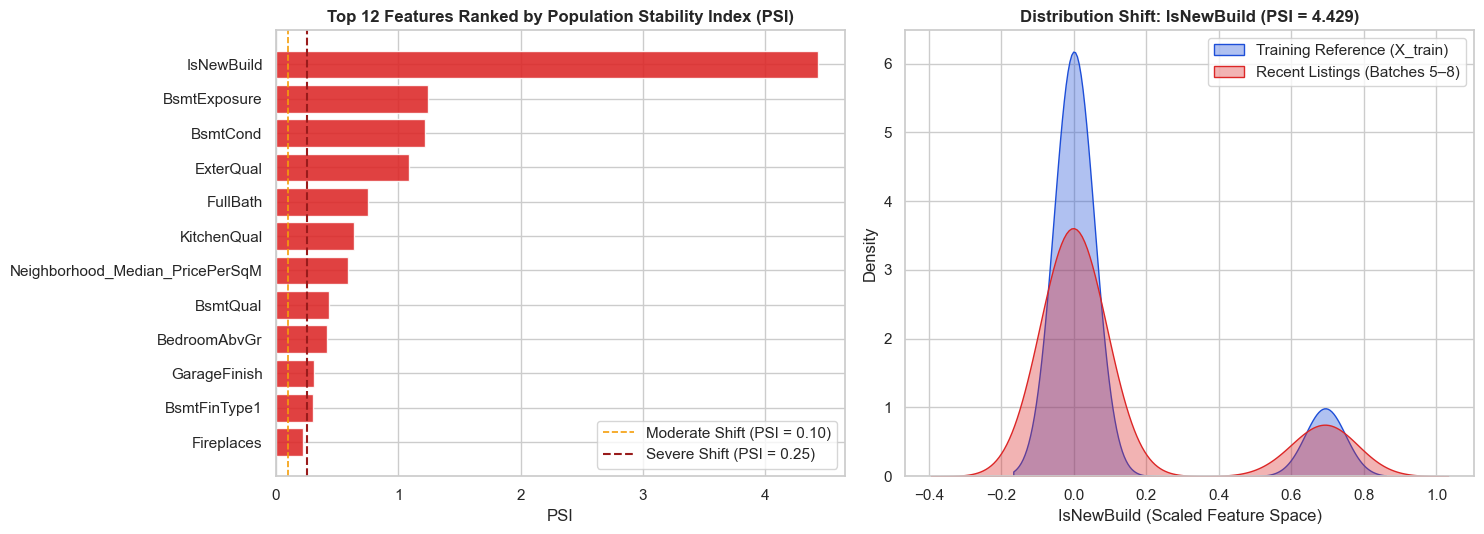

In [8]:
# Visualize Top 12 Features by PSI and Distribution Shift for Top Drifted Driver
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

top12 = drift_df.head(12).iloc[::-1]
colors = ['#dc2626' if d else '#2563eb' for d in top12['drift_detected']]
axes[0].barh(top12['feature'], top12['psi'], color=colors, alpha=0.88)
axes[0].axvline(0.10, color='#f59e0b', linestyle='--', linewidth=1.2, label='Moderate Shift (PSI = 0.10)')
axes[0].axvline(0.25, color='#991b1b', linestyle='--', linewidth=1.5, label='Severe Shift (PSI = 0.25)')
axes[0].set_title('Top 12 Features Ranked by Population Stability Index (PSI)', fontweight='bold')
axes[0].set_xlabel('PSI')
axes[0].legend(loc='lower right')

top_feat = drift_df.iloc[0]['feature']
sns.kdeplot(X_train[top_feat], ax=axes[1], label='Training Reference (X_train)', fill=True, alpha=0.35, color='#1d4ed8')
sns.kdeplot(recent_window_df[top_feat], ax=axes[1], label='Recent Listings (Batches 5–8)', fill=True, alpha=0.35, color='#dc2626')
axes[1].set_title(f'Distribution Shift: {top_feat} (PSI = {drift_df.iloc[0]["psi"]:.3f})', fontweight='bold')
axes[1].set_xlabel(f'{top_feat} (Scaled Feature Space)')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, 'module7_data_drift_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()

## 4. Rolling Prediction Error Tracking Over Time (RMSE & MAE)
As realized closing prices arrive for listed properties, we monitor both **weekly batch error** and **sliding-window rolling error** (`window_size = 180`, `step_size = 60`) against the baseline cross-validation benchmark (`RMSE_log = 0.13207`) and the +20% degradation alert threshold (`0.15848`).

In [9]:
batch_metrics_df, rolling_metrics_df = compute_rolling_error_metrics(
    stream_df=stream_df,
    window_size=180,
    step_size=60,
)

display(batch_metrics_df)
display(rolling_metrics_df.head(10))

,batch_id,batch_date,n_samples,rmse_log,mae_log,rmse_usd,mae_usd,mape_pct,r2_log
0,1,2026-01-05,120,0.12650,0.10135,25927.98,18906.84,10.16,0.9021
1,2,2026-01-12,120,0.14836,0.12375,28885.38,22159.74,12.67,0.8508
2,3,2026-01-19,120,0.13232,0.10419,24559.70,18102.37,10.44,0.8998
3,4,2026-01-26,120,0.13997,0.11498,29802.67,22371.30,11.37,0.8720
4,5,2026-02-02,120,0.11574,0.09356,27656.13,19808.21,9.26,0.9236
5,6,2026-02-09,120,0.15829,0.12276,41542.06,27192.02,11.52,0.8632
6,7,2026-02-16,120,0.13537,0.10769,35972.05,24617.04,10.35,0.8681
7,8,2026-02-23,120,0.16518,0.13471,36546.38,28271.41,12.69,0.8202


,window_end_idx,window_end_date,window_size,rolling_rmse_log,rolling_mae_log,rolling_rmse_usd,rolling_mae_usd
0,180,2026-01-12,180,0.12906,0.10557,25753.54,19402.00
1,240,2026-01-12,180,0.14150,0.11502,27928.77,20833.18
2,300,2026-01-19,180,0.14838,0.12243,27957.62,21359.13
3,360,2026-01-19,180,0.14268,0.11395,27263.37,20043.96
4,420,2026-01-26,180,0.13187,0.10593,23885.48,18237.43
5,480,2026-01-26,180,0.13188,0.10618,27728.44,20396.48
6,540,2026-02-02,180,0.13337,0.10950,29047.23,21706.04
7,600,2026-02-02,180,0.12756,0.10256,30555.58,21950.49
8,660,2026-02-09,180,0.13538,0.10426,34315.29,22390.73
9,720,2026-02-09,180,0.14459,0.11136,37533.90,24541.64


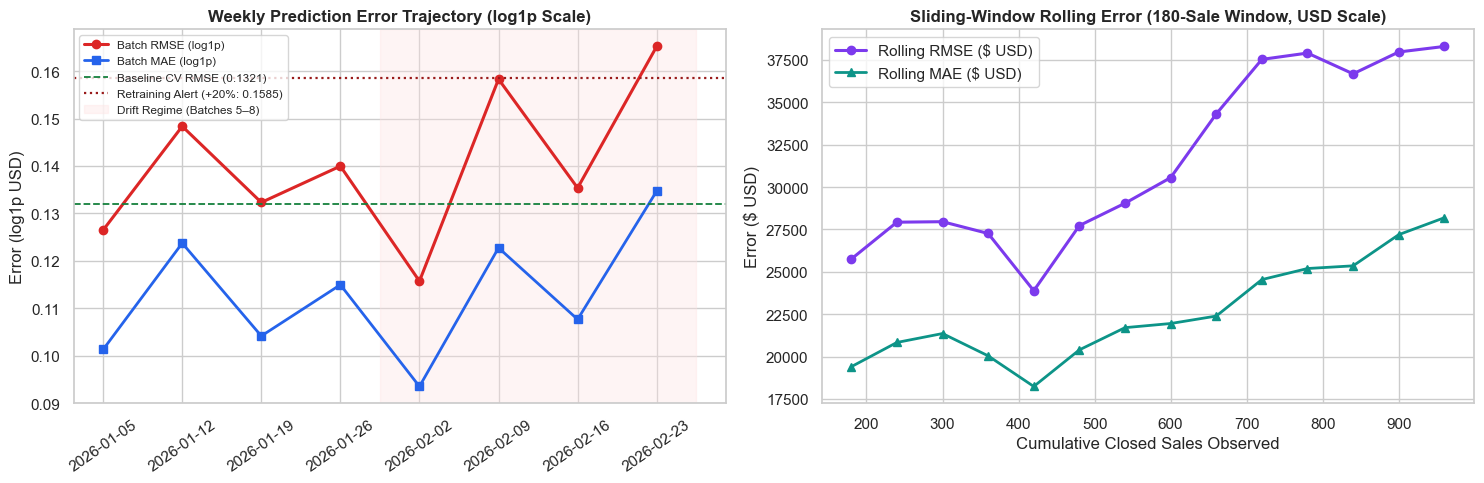

In [10]:
# Plot Weekly & Rolling RMSE / MAE Degradation Over Time
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Weekly Batch RMSE_log and MAE_log
axes[0].plot(batch_metrics_df['batch_date'], batch_metrics_df['rmse_log'], marker='o', linewidth=2.2, color='#dc2626', label='Batch RMSE (log1p)')
axes[0].plot(batch_metrics_df['batch_date'], batch_metrics_df['mae_log'], marker='s', linewidth=2.0, color='#2563eb', label='Batch MAE (log1p)')
axes[0].axhline(baseline_rmse_log, color='#15803d', linestyle='--', linewidth=1.3, label=f'Baseline CV RMSE ({baseline_rmse_log:.4f})')
axes[0].axhline(baseline_rmse_log * 1.20, color='#991b1b', linestyle=':', linewidth=1.6, label=f'Retraining Alert (+20%: {baseline_rmse_log * 1.20:.4f})')
axes[0].axvspan(3.5, 7.5, color='#fee2e2', alpha=0.35, label='Drift Regime (Batches 5–8)')
axes[0].set_title('Weekly Prediction Error Trajectory (log1p Scale)', fontweight='bold')
axes[0].set_ylabel('Error (log1p USD)')
axes[0].tick_params(axis='x', rotation=35)
axes[0].legend(fontsize=8.5)

# Right: Sliding-Window Rolling RMSE_USD and MAE_USD
axes[1].plot(rolling_metrics_df['window_end_idx'], rolling_metrics_df['rolling_rmse_usd'], marker='o', linewidth=2.2, color='#7c3aed', label='Rolling RMSE ($ USD)')
axes[1].plot(rolling_metrics_df['window_end_idx'], rolling_metrics_df['rolling_mae_usd'], marker='^', linewidth=2.0, color='#0d9488', label='Rolling MAE ($ USD)')
axes[1].set_title('Sliding-Window Rolling Error (180-Sale Window, USD Scale)', fontweight='bold')
axes[1].set_xlabel('Cumulative Closed Sales Observed')
axes[1].set_ylabel('Error ($ USD)')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, 'module7_rolling_error_tracking.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Retraining Governance Triggers & Monitoring Dashboard Export
Finally, we evaluate automated retraining rules and export:
- `reports/module7_monitoring_dashboard.html` (Evidently interactive report or built-in governance HTML dashboard)
- `reports/module7_feature_drift_report.csv`
- `reports/module7_rolling_error_metrics.csv`
- `reports/module7_monitoring_audit.json`

In [11]:
trigger_decision = evaluate_retraining_triggers(
    drift_df=drift_df,
    batch_metrics_df=batch_metrics_df,
    baseline_rmse_log=baseline_rmse_log,
    max_drifted_feature_share=0.15,
    max_psi_threshold=0.25,
    rmse_degradation_factor=1.20,
    min_new_labeled_sales=250,
)

print(json.dumps(trigger_decision, indent=2))

dashboard_html_path = os.path.join(reports_dir, 'module7_monitoring_dashboard.html')
dash_info = generate_monitoring_dashboard(
    reference_df=X_train,
    current_df=recent_window_df,
    drift_df=drift_df,
    batch_metrics_df=batch_metrics_df,
    trigger_decision=trigger_decision,
    output_html_path=dashboard_html_path,
)

drift_df.to_csv(os.path.join(reports_dir, 'module7_feature_drift_report.csv'), index=False)
batch_metrics_df.to_csv(os.path.join(reports_dir, 'module7_rolling_error_metrics.csv'), index=False)

print('\nDashboard Export Summary:')
print(json.dumps(dash_info, indent=2))

{
  "retraining_recommended": true,
  "active_alert_count": 3,
  "active_alerts": [
    "covariate_drift_share_exceeded",
    "severe_feature_psi_exceeded",
    "rolling_rmse_degradation_exceeded"
  ],
  "triggers": {
    "covariate_drift_share_exceeded": {
      "triggered": true,
      "observed": 0.3,
      "threshold": 0.15,
      "description": "Share of drifted features (30.0%) >= 15.0%"
    },
    "severe_feature_psi_exceeded": {
      "triggered": true,
      "observed": 4.42882,
      "threshold": 0.25,
      "description": "Maximum feature PSI (4.4288) >= 0.25"
    },
    "rolling_rmse_degradation_exceeded": {
      "triggered": true,
      "observed": 0.16518,
      "threshold": 0.15849,
      "description": "Latest batch RMSE_log (0.16518) >= 0.15849 (+20% over baseline 0.13207)"
    },
    "new_labeled_volume_ready": {
      "triggered": true,
      "observed": 960,
      "threshold": 250,
      "description": "Accumulated closed sales (960) >= 250 minimum retraining sampl